# 卷积神经网络

本实验结合一个实际分类任务，看看如何使用 Pytorch 训练 CNN
这个任务，是识别 CIFAR-10 数据集中的图像，共有 10 个类别。


## 导入模块


In [1]:
import torch # 张量运算，自动微分
import torch.nn as nn # d定义神经网络层和损失函数
import torch.optim as optim # 优化器

from torch.utils.data import DataLoader, random_split # 加载数据，划分训练集和验证集
from torchvision import datasets, transforms # 加载CIFAR-10数据集，图像预处理

import matplotlib.pyplot as plt

## 数据集

我们使用 CIFAR-10 数据集，每张图像大小为 32x32，下载文件约 163MB。数据集包含 60000 张 32x32 的彩色图像，共分为 10 个类别，每个类别有 6000 张图像。测试集包含 10000 张图像，训练集有 50000 张图像。

In [2]:
# 图像预处理，将 PIL 图片或 NumPy 图像数组转换为张量，并且归一化到 [0, 1] 之间
transform = transforms.Compose([
    transforms.ToTensor(),
])

`ToTensor()` 主要做两件事
* 将图像的数据排列方式从 HWC 转为 CHW，即从 (高, 宽, 通道数) 转为 (通道数, 高, 宽)
* 将图像的像素值从 [0, 255] 转为 [0, 1]

In [3]:

# 下载并加载数据
# 训练集
full_train_dataset = datasets.CIFAR10(
    root="./data",          # 数据集保存位置
    train=True,             # 加载官方训练集
    download=True,          # 本地没有时自动下载
    transform=transform     # 对每张图片执行预处理
)

# 测试集
test_dataset = datasets.CIFAR10(
    root="./data",          # 数据集保存位置
    train=False,            # 加载官方测试集
    download=True,          # 本地没有时自动下载
    transform=transform     # 对每张图片执行预处理
)

这里我们再把 50000 张图片划分成 训练集 和 验证集，验证集占 10%。

In [4]:
# 固定随机种子
generator = torch.Generator().manual_seed(42)

# 划分训练集和验证集
train_dataset, val_dataset = random_split(
    full_train_dataset,    
    [45000, 5000],          # 训练集 45000 张，验证集 5000 张
    generator=generator     
)

print(f"训练集大小: {len(train_dataset)}")
print(f"验证集大小: {len(val_dataset)}")
print(f"测试集大小: {len(test_dataset)}")

训练集大小: 45000
验证集大小: 5000
测试集大小: 10000



神经网络通常使用小批量梯度下降，我们设置 $batchsize=64$，也就是每次处理 64 张图片。

In [5]:
batch_size = 64

# 训练集，打乱顺序
train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True, # 打乱顺序
)

# 验证集，不打乱顺序
val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=batch_size,
    shuffle=False, # 不打乱顺序
)

# 测试集，不打乱顺序
test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=batch_size,
    shuffle=False, # 不打乱顺序
)

我们检查一个 batch 的数据，看看是否正确。

In [6]:
# iter() 创建迭代器
# next() 获取第一个 batch
image, labels = next(iter(train_loader))

print(f"图片形状: {image.shape}")
print(f"标签形状: {labels.shape}")

图片形状: torch.Size([64, 3, 32, 32])
标签形状: torch.Size([64])


## 模型构建

首先是定义 CNN 模型，我们使用 `nn.Module` 来定义一个神经网络，继承这个类，定义自己的网络结构。

In [7]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # 第一部分：卷积特征提取
        self.feature = nn.Sequential(
            # 第一个卷积层
            nn.Conv2d(
                in_channels=3, # 输入通道数，RGB 图像为 3
                out_channels=16, # 输出通道数，卷积核数量
                kernel_size=3, # 卷积核大小
                stride=1, # 步长
                padding=1, # 边缘填充，保持空间尺寸不变
            ),
            # 激活函数
            nn.ReLU(), 
            # 最大池化
            nn.MaxPool2d(kernel_size=2, stride=2),
            # 第二个卷积层
            nn.Conv2d(
                in_channels=16, # 输入通道数，上一个卷积层的输出通道数
                out_channels=32, 
                kernel_size=3,
                stride=1, 
                padding=1, 
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # 第二部分：逻辑回归分类器
        self.classifier = nn.Sequential(
            # 将每个特征图的三维度特征图展平
            # 输入(B, 32, 8, 8)，输出(B, 32*8*8=2048)
            nn.Flatten(),
            # 全连接层
            nn.Linear(32*8*8, 10) # 输入 2048，输出 10
        )

    # 前向传播
    def forward(self, x):
        # 通过卷积层提取图像特征
        x = self.feature(x)
        # 通过全连接层进行分类
        x = self.classifier(x)
        # 返回原始预测分数 logits
        return x



为什么不需要定义反向传播？
因为 PyTorch 使用了自动微分，在调用 `loss.backward()` 时，PyTorch 会自动计算梯度。

现在来验证模型的输出形状

In [8]:
# 创建模型实例
model = SimpleCNN()

# 构造一个模拟 Batch
# 64 张 RGB 图片，每张 32×32
x = torch.randn(64, 3, 32, 32)

# 前向传播
outputs = model(x)

print(outputs.shape)

torch.Size([64, 10])


## 损失函数和优化器

首先选择计算设备，我们使用 GPU 训练，如果 GPU 不支持，则使用 CPU。

In [9]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("当前设备：", device)

# 将模型的参数移动到计算设备
model = SimpleCNN().to(device)


当前设备： cuda


In [10]:
# 损失函数使用交叉熵损失
criterion = nn.CrossEntropyLoss()


`nn.CrossEntropyLoss`接收的是原始预测分数 logits，而不是概率，所以不需要再使用 `nn.Softmax`

In [11]:
# 定义优化器
optimizer = optim.Adam(
    model.parameters(),  # 获取所有可训练参数
    lr=0.001 # 学习率
)

## 训练函数封装

我们将训练一个 Epoch 的过程封装成函数
epoch 指完整遍历一次整个训练数据集的过程

In [12]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):
    # 切换到训练模式
    model.train()

    running_loss = 0.0    # 记录整个 Epoch 的累计损失
    correct = 0     # 记录预测正确的样本数量
    total = 0       # 记录样本总数

    # 每次循环取出一个 Batch
    for images, labels in train_loader:
        # 将图片和标签移动到计算设备
        images = images.to(device)
        labels = labels.to(device)
        # 清空上一轮累积的梯度
        optimizer.zero_grad()
        # 前向传播
        outputs = model(images)
        # 计算交叉熵损失
        loss = criterion(outputs, labels)
        # 反向传播，自动计算模型各参数的梯度。梯度存储在 parameters.grad 中
        loss.backward()
        # 使用优化器更新模型参数
        optimizer.step()
        # 统计训练指标
        batch_size = images.size(0) # 当前 Batch 的样本数量
        running_loss += loss.item() * batch_size # loss.item() 是当前 Batch 的平均损失
        predictions = outputs.argmax(dim=1) # dim=1 表示在 10 个类别分数中取最大值
        correct += (predictions == labels).sum().item() # 统计预测正确的样本数量
        total += batch_size # 统计样本总数

    # 整个 Epoch 的平均损失
    epoch_loss = running_loss / total
    # 整个 Epoch 的准确率
    epoch_acc = correct / total

    return epoch_loss, epoch_acc


## 验证函数封装

训练过程中，我们还需要观察模型在验证集上的表现

In [13]:
def evaluate(model, data_loader, criterion, device):
    # 切换到评估模式
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad(): # 不计算梯度，节省内存
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            batch_size = images.size(0)
            running_loss += loss.item() * batch_size
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += batch_size

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

## 开始训练

In [14]:


# 训练轮数
num_epochs = 10

# 记录每轮训练和验证的指标
train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

# 保存验证准确率最高时的模型
best_val_accuracy = 0.0

for epoch in range(num_epochs):
    # 训练一个 epoch
    train_loss, train_acc = train_one_epoch(
        model=model,
        train_loader=train_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=device
    )
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    # 在验证集上评估模型
    val_loss, val_acc = evaluate(
        model=model,
        data_loader=val_loader,
        criterion=criterion,
        device=device
    )
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    if val_acc > best_val_accuracy:
        best_val_accuracy = val_acc
        # 保存模型
        torch.save(
            model.state_dict(), 
            "best_cnn.pth"
        )
    
    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f}, "
        f"Train Acc: {train_acc * 100:.2f}% | "
        f"Val Loss: {val_loss:.4f}, "
        f"Val Acc: {val_acc * 100:.2f}%"
    )



Epoch [1/10] Train Loss: 1.6289, Train Acc: 41.97% | Val Loss: 1.4538, Val Acc: 48.24%
Epoch [2/10] Train Loss: 1.3116, Train Acc: 54.07% | Val Loss: 1.2637, Val Acc: 55.14%
Epoch [3/10] Train Loss: 1.1916, Train Acc: 58.34% | Val Loss: 1.1810, Val Acc: 58.74%
Epoch [4/10] Train Loss: 1.1109, Train Acc: 61.04% | Val Loss: 1.2031, Val Acc: 57.52%
Epoch [5/10] Train Loss: 1.0537, Train Acc: 63.40% | Val Loss: 1.0878, Val Acc: 62.66%
Epoch [6/10] Train Loss: 1.0030, Train Acc: 65.25% | Val Loss: 1.0509, Val Acc: 63.90%
Epoch [7/10] Train Loss: 0.9736, Train Acc: 66.35% | Val Loss: 1.0265, Val Acc: 64.84%
Epoch [8/10] Train Loss: 0.9417, Train Acc: 67.52% | Val Loss: 1.0686, Val Acc: 63.06%
Epoch [9/10] Train Loss: 0.9115, Train Acc: 68.69% | Val Loss: 1.0320, Val Acc: 64.58%
Epoch [10/10] Train Loss: 0.8903, Train Acc: 69.14% | Val Loss: 1.0462, Val Acc: 64.34%


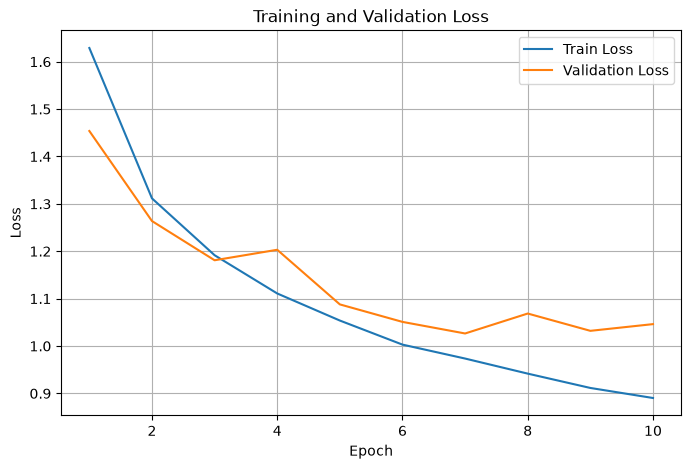

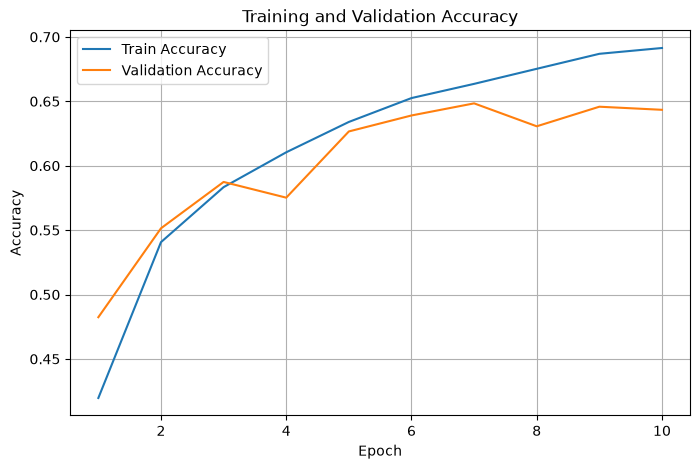

In [15]:
#绘制训练曲线，可视化训练过程
# Epoch 编号
epochs = range(1, num_epochs + 1)

# 绘制损失曲线
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_losses,
    label="Train Loss"
)

plt.plot(
    epochs,
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_accuracies,
    label="Train Accuracy"
)

plt.plot(
    epochs,
    val_accuracies,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

## 最终评估

In [16]:
# 加载验证准确率最高时保存的参数
model.load_state_dict(
    torch.load(
        "best_cnn.pth",
        map_location=device,
        weights_only=True
    )
)

# 在测试集上评估
test_loss, test_acc = evaluate(
    model=model,
    data_loader=test_loader,
    criterion=criterion,
    device=device
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

Test Loss: 1.0149
Test Accuracy: 65.25%


看看模型如何预测一张具体图片

真实类别： cat
预测类别： cat
预测概率：52.50%


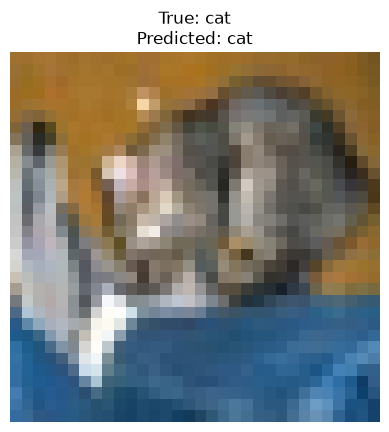

In [17]:
# 从测试集中取出一张图片和真实标签
image, label = test_dataset[0]

# image 原本的形状是 (3, 32, 32)
# unsqueeze(0) 添加 Batch 维度
#
# (3, 32, 32) -> (1, 3, 32, 32)
input_image = image.unsqueeze(0).to(device)

# 切换到评估模式
model.eval()

with torch.no_grad():

    # 得到 10 个类别的 logits
    outputs = model(input_image)

    # 计算各类别的预测概率
    probabilities = torch.softmax(outputs, dim=1)

    # 找到预测概率最高的类别
    predicted_class = probabilities.argmax(dim=1).item()

    # 取出最高的预测概率
    confidence = probabilities.max(dim=1).values.item()

# CIFAR-10 的类别名称
classes = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("真实类别：", classes[label])
print("预测类别：", classes[predicted_class])
print(f"预测概率：{confidence * 100:.2f}%")

# 将图片从 (C, H, W) 转换为 (H, W, C)
# 因为 matplotlib 使用通道在最后的格式
plt.imshow(image.permute(1, 2, 0))

plt.title(
    f"True: {classes[label]}\n"
    f"Predicted: {classes[predicted_class]}"
)

plt.axis("off")
plt.show()